In [4]:
import os
import time
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("Observatorio_Brecha_Digital_Colombia") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("SESIÓN DE APACHE SPARK INICIADA")
print("Versión de Spark:", spark.version)
print("Modo de ejecución (Master):", spark.sparkContext.master)
print("Paralelismo por defecto (Particiones/Núcleos):", spark.sparkContext.defaultParallelism)

ruta_csv = "../data/processed/tic_limpio_2025.csv"
tamano_mb = os.path.getsize(ruta_csv) / (1024 * 1024)

df_spark = spark.read.csv(ruta_csv, header=True, inferSchema=True)

total_registros = df_spark.count()
num_particiones = df_spark.rdd.getNumPartitions()

print(f"\nArchivo procesado: {ruta_csv} ({tamano_mb:.2f} MB)")
print(f"Total de registros cargados en Spark: {total_registros:,}")
print(f"Total de columnas: {len(df_spark.columns)}")
print(f"Número de particiones distribuidas en Spark: {num_particiones}")

SESIÓN DE APACHE SPARK INICIADA
Versión de Spark: 4.2.1
Modo de ejecución (Master): local[*]
Paralelismo por defecto (Particiones/Núcleos): 12

Archivo procesado: ../data/processed/tic_limpio_2025.csv (43.55 MB)
Total de registros cargados en Spark: 221,043
Total de columnas: 37
Número de particiones distribuidas en Spark: 11


In [5]:
def ejecutar_analitica_spark(sdf):
    res_depto_zona = sdf.groupBy("NOMBRE_DEPARTAMENTO", "ZONA").agg(
        F.count("*").alias("Muestra_Personas"),
        F.round(F.sum("FEX_C"), 0).alias("Poblacion_Estimada"),
        F.round((F.sum(F.col("USA_INTERNET") * F.col("FEX_C")) / F.sum("FEX_C")) * 100, 2).alias("Pct_Usa_Internet"),
        F.round((F.sum(F.col("P1085S1") * F.col("FEX_C")) / F.sum("FEX_C")) * 100, 2).alias("Pct_Internet_Hogar"),
        F.round((F.sum(F.col("USA_COMPUTADOR") * F.col("FEX_C")) / F.sum("FEX_C")) * 100, 2).alias("Pct_Usa_Computador"),
        F.round((F.sum(F.col("USA_CELULAR") * F.col("FEX_C")) / F.sum("FEX_C")) * 100, 2).alias("Pct_Usa_Celular"),
        F.round(F.sum(F.col("PUNTAJE_CONECTIVIDAD") * F.col("FEX_C")) / F.sum("FEX_C"), 2).alias("Indice_Conectividad_Prom"),
        F.round(F.avg("PERCAPITA"), 0).alias("Ingreso_Percapita_Prom")
    ).orderBy(F.desc("Pct_Usa_Internet"))
    
    res_razones = sdf.filter(F.col("USA_INTERNET") == 0).groupBy("ZONA", "RAZON_NO_INTERNET").agg(
        F.count("*").alias("Muestra_Sin_Internet"),
        F.round(F.sum("FEX_C"), 0).alias("Poblacion_Sin_Internet")
    ).orderBy("ZONA", F.desc("Poblacion_Sin_Internet"))
    
    pdf_depto = res_depto_zona.toPandas()
    pdf_razones = res_razones.toPandas()
    return pdf_depto, pdf_razones

t0 = time.perf_counter()
df_1_part = df_spark.repartition(1)
_, _ = ejecutar_analitica_spark(df_1_part)
t_spark_1 = time.perf_counter() - t0

nucleos = spark.sparkContext.defaultParallelism
t0 = time.perf_counter()
df_n_part = df_spark.repartition(nucleos)
pdf_depto_zona, pdf_razones = ejecutar_analitica_spark(df_n_part)
t_spark_dist = time.perf_counter() - t0

speedup_spark = t_spark_1 / t_spark_dist
eficiencia_spark = (speedup_spark / nucleos) * 100

df_metricas_spark = pd.DataFrame([
    {"Configuración Spark": "Spark 1 Partición (Secuencial)", "Particiones/Núcleos": 1, "Tiempo (s)": round(t_spark_1, 4), "Speedup": 1.0, "Eficiencia (%)": 100.0},
    {"Configuración Spark": f"Spark Distribuido ({nucleos} Particiones)", "Particiones/Núcleos": nucleos, "Tiempo (s)": round(t_spark_dist, 4), "Speedup": round(speedup_spark, 4), "Eficiencia (%)": round(eficiencia_spark, 2)}
])

print("--- RENDIMIENTO APACHE SPARK (221,043 REGISTROS) ---")
display(df_metricas_spark)

print("\nTOP 10 DEPARTAMENTO / ZONA POR ACCESO A INTERNET")
display(pdf_depto_zona.head(10))

df_metricas_spark.to_csv("../evidencias/capturas_cpd/metricas_spark.csv", index=False)
pdf_depto_zona.to_csv("../data/processed/resumen_brecha_depto_zona.csv", index=False, encoding="utf-8-sig")
pdf_razones.to_csv("../data/processed/resumen_razones_no_internet.csv", index=False, encoding="utf-8-sig")
print("\nTablas resumidas guardadas exitosamente.")

C:\Users\USUARIO\anaconda3\envs\BrechaDigital\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
C:\Users\USUARIO\anaconda3\envs\BrechaDigital\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
C:\Users\USUARIO\anaconda3\envs\BrechaDigital\lib\site-packages\pyspark\sql\pand

--- RENDIMIENTO APACHE SPARK (221,043 REGISTROS) ---


,Configuración Spark,Particiones/Núcleos,Tiempo (s),Speedup,Eficiencia (%)
0,Spark 1 Partición (Secuencial),1,3.2756,1.0000,100.00
1,Spark Distribuido (12 Particiones),12,11.9248,0.2747,2.29



TOP 10 DEPARTAMENTO / ZONA POR ACCESO A INTERNET


,NOMBRE_DEPARTAMENTO,ZONA,Muestra_Personas,Poblacion_Estimada,Pct_Usa_Internet,Pct_Internet_Hogar,Pct_Usa_Computador,Pct_Usa_Celular,Indice_Conectividad_Prom,Ingreso_Percapita_Prom
0,Valle del Cauca,Urbano,4014,3822823.0,90.26,87.08,43.09,85.49,3.06,1345782.0
1,Risaralda,Urbano,3104,775046.0,90.03,89.13,37.50,87.57,3.04,1423440.0
2,Atlántico,Urbano,4181,2577753.0,89.46,88.23,31.70,79.67,2.89,1173286.0
3,Santander,Urbano,4321,1760765.0,89.29,88.10,41.52,84.52,3.03,1460102.0
4,San Andrés y Providencia,Urbano,2016,41678.0,88.46,87.69,33.53,88.09,2.98,1798546.0
5,Norte de Santander,Urbano,3414,1258278.0,88.45,86.86,32.27,79.67,2.87,1017530.0
6,Boyacá,Urbano,3687,750936.0,87.20,84.88,43.08,85.34,3.01,1457967.0
7,Caldas,Urbano,3230,795113.0,87.14,86.38,39.92,87.08,3.01,1740815.0
8,Cundinamarca,Urbano,3603,2764994.0,86.86,84.30,43.81,85.55,3.01,1381018.0
9,Bolívar,Urbano,4490,1564859.0,86.77,79.45,34.50,77.30,2.78,1008635.0



Tablas resumidas guardadas exitosamente.


In [14]:
import glob
import os
import pandas as pd

archivos_mp = glob.glob("../evidencias/capturas_cpd/*metricas*.csv") + glob.glob("../data/processed/*metricas*.csv")
archivos_mp = [f for f in archivos_mp if "spark" not in os.path.basename(f).lower() and "completas" not in os.path.basename(f).lower()]

if not archivos_mp:
    raise FileNotFoundError("No se encontró el CSV de multiprocessing. Verifica la ruta o el nombre del archivo.")

df_mp = pd.read_csv(archivos_mp[0])

df_mp = df_mp.rename(columns={
    df_mp.columns[0]: "Configuración",
    df_mp.columns[1]: "Particiones/Núcleos",
    df_mp.columns[2]: "Tiempo (s)",
    df_mp.columns[3]: "Speedup",
    df_mp.columns[4]: "Eficiencia (%)"
})
df_mp.insert(1, "Etapa", "Limpieza y transformación")

df_metricas_spark = pd.DataFrame([
    {
        "Configuración": "Apache Spark (1 partición)",
        "Etapa": "Consulta analítica Spark",
        "Particiones/Núcleos": 1,
        "Tiempo (s)": round(t_spark_1, 4),
        "Speedup": 1.0000,
        "Eficiencia (%)": 100.00
    },
    {
        "Configuración": f"Apache Spark ({nucleos} particiones)",
        "Etapa": "Consulta analítica Spark",
        "Particiones/Núcleos": nucleos,
        "Tiempo (s)": round(t_spark_dist, 4),
        "Speedup": round(speedup_spark, 4),
        "Eficiencia (%)": round(eficiencia_spark, 2)
    }
])

df_metricas_completo = pd.concat([df_mp, df_metricas_spark], ignore_index=True)

print(f"Archivo de multiprocessing cargado: {archivos_mp[0]}")
print(" RENDIMIENTO CONSOLIDADO CPD")
display(df_metricas_completo)

df_metricas_completo.to_csv("../evidencias/capturas_cpd/metricas_cpd_completas.csv", index=False, encoding="utf-8-sig")

Archivo de multiprocessing cargado: ../evidencias/capturas_cpd\metricas_multiprocessing.csv
 RENDIMIENTO CONSOLIDADO CPD


,Configuración,Etapa,Particiones/Núcleos,Tiempo (s),Speedup,Eficiencia (%)
0,Secuencial (1 proceso),Limpieza y transformación,1,3.9308,1.0000,100.00
1,Paralelo (2 procesos),Limpieza y transformación,2,8.8005,0.4467,22.33
2,Paralelo (4 procesos),Limpieza y transformación,4,6.0525,0.6495,16.24
3,Apache Spark (1 partición),Consulta analítica Spark,1,3.2756,1.0000,100.00
4,Apache Spark (12 particiones),Consulta analítica Spark,12,11.9248,0.2747,2.29


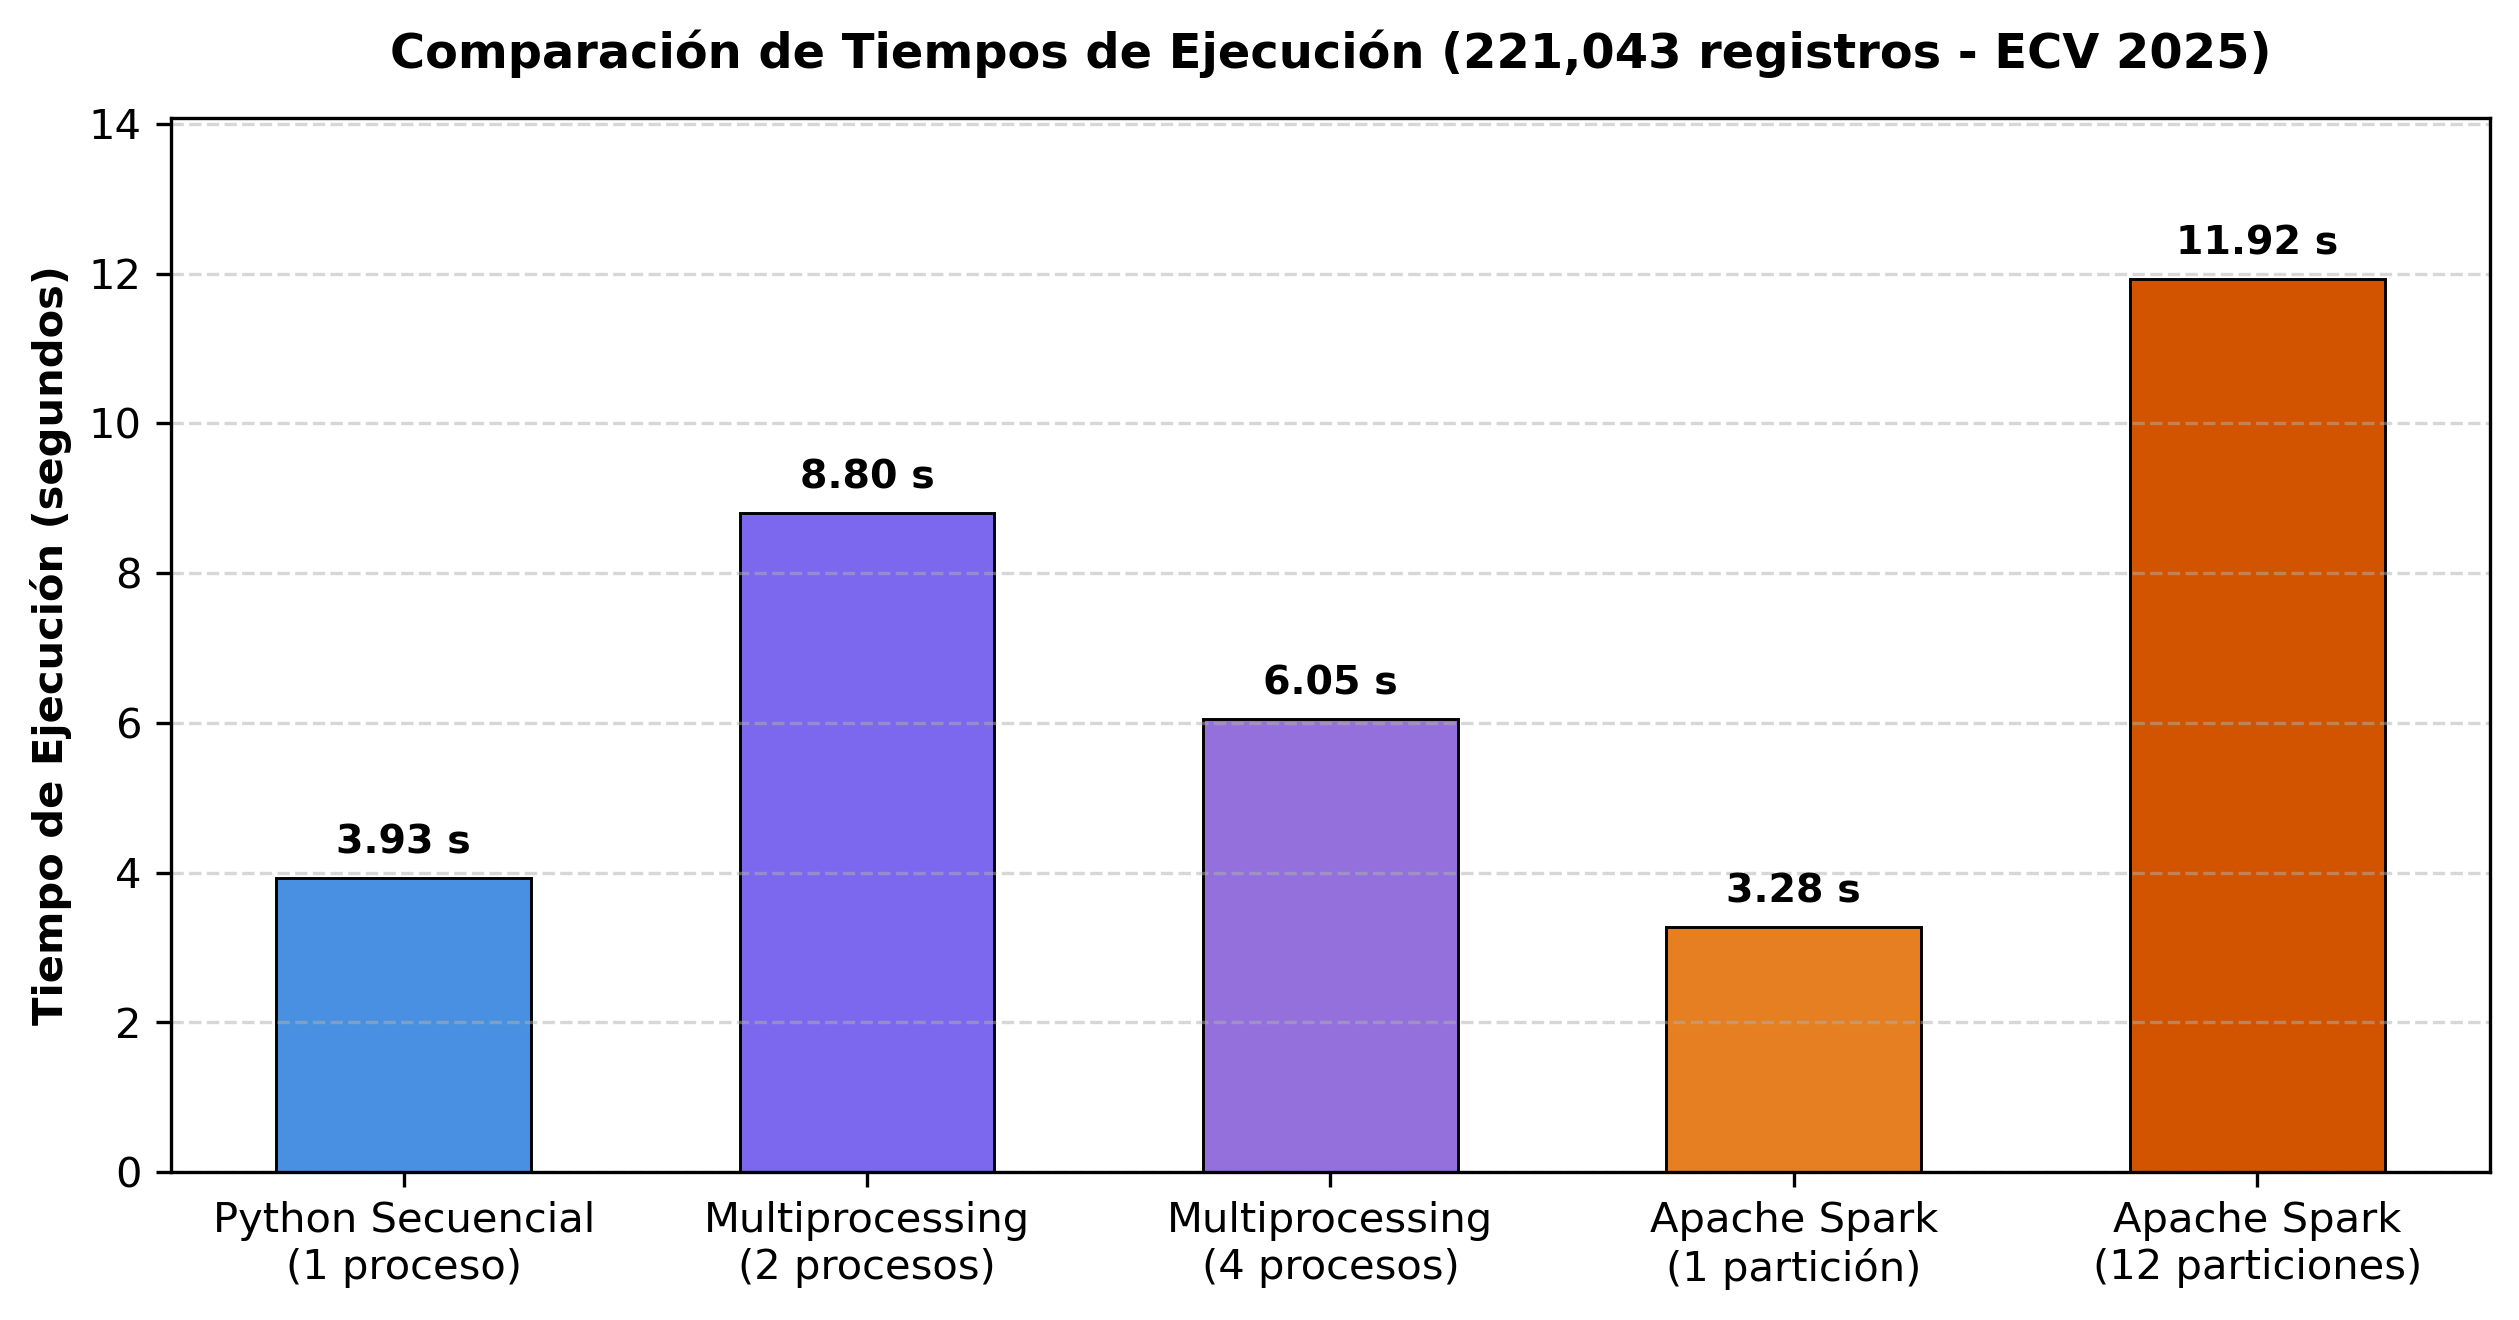

Gráfica generada lista para Overleaf: ../evidencias/capturas_cpd/06_comparacion_tiempos_cpd.png


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

df_mp = pd.read_csv("../evidencias/capturas_cpd/metricas_multiprocessing.csv")
df_sp = pd.read_csv("../evidencias/capturas_cpd/metricas_spark.csv")

etiquetas = [
    "Python Secuencial\n(1 proceso)",
    "Multiprocessing\n(2 procesos)",
    "Multiprocessing\n(4 procesos)",
    "Apache Spark\n(1 partición)",
    "Apache Spark\n(12 particiones)"
]
tiempos = [
    df_mp.loc[0, "Tiempo Promedio (s)"],
    df_mp.loc[1, "Tiempo Promedio (s)"],
    df_mp.loc[2, "Tiempo Promedio (s)"],
    df_sp.loc[0, "Tiempo (s)"],
    df_sp.loc[1, "Tiempo (s)"]
]
colores = ["#4A90E2", "#7B68EE", "#9370DB", "#E67E22", "#D35400"]

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=300)
barras = ax.bar(etiquetas, tiempos, color=colores, width=0.55, edgecolor="black", linewidth=0.7)

ax.set_title("Comparación de Tiempos de Ejecución (221,043 registros - ECV 2025)", fontsize=11.5, fontweight="bold", pad=12)
ax.set_ylabel("Tiempo de Ejecución (segundos)", fontsize=10, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_ylim(0, max(tiempos) * 1.18)

for barra in barras:
    altura = barra.get_height()
    ax.annotate(f"{altura:.2f} s",
                xy=(barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.tight_layout()
ruta_fig = "../evidencias/capturas_cpd/06_comparacion_tiempos_cpd.png"
plt.savefig(ruta_fig, dpi=300)
plt.show()
print(f"Gráfica generada lista para Overleaf: {ruta_fig}")

In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Estilo clásico sobrio (sin efectos recargados)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.edgecolor"] = "#555555"
plt.rcParams["axes.linewidth"] = 0.8

os.makedirs("graficas_cpd_varias", exist_ok=True)

df = pd.DataFrame([
    {
        "config": "Python secuencial (1)",
        "experimento": "Limpieza y transformación",
        "unidades": 1,
        "tiempo_s": 3.9308,
        "base_s": 3.9308,
        "corridas": 3,
    },
    {
        "config": "Multiprocessing (2)",
        "experimento": "Limpieza y transformación",
        "unidades": 2,
        "tiempo_s": 8.8005,
        "base_s": 3.9308,
        "corridas": 3,
    },
    {
        "config": "Multiprocessing (4)",
        "experimento": "Limpieza y transformación",
        "unidades": 4,
        "tiempo_s": 6.0525,
        "base_s": 3.9308,
        "corridas": 3,
    },
    {
        "config": "Spark (1 partición)",
        "experimento": "Consulta analítica Spark",
        "unidades": 1,
        "tiempo_s": 3.2756,
        "base_s": 3.2756,
        "corridas": 1,
    },
    {
        "config": "Spark (12 particiones)",
        "experimento": "Consulta analítica Spark",
        "unidades": 12,
        "tiempo_s": 11.9248,
        "base_s": 3.2756,
        "corridas": 1,
    },
])

df["speedup"] = df["base_s"] / df["tiempo_s"]
df["eficiencia_pct"] = (df["speedup"] / df["unidades"]) * 100
df["diff_s"] = df["tiempo_s"] - df["base_s"]

# ---------------------------------------------------------
# 1. Barras horizontales: Tiempo total por configuración
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.0, 4.2), dpi=300)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

df_ord = df.iloc[::-1]
barras = ax.barh(
    df_ord["config"],
    df_ord["tiempo_s"],
    height=0.52,
    color="#5E4B8B",
    edgecolor="#2B2142",
    linewidth=0.8,
)

ax.xaxis.grid(True, linestyle="--", linewidth=0.6, color="#D0D0D0")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Tiempo de ejecución (s)", fontsize=9.5, color="#222222")
ax.set_title("Tiempo de ejecución por configuración (ECV 2025)", fontsize=10.5, color="#111111", pad=10)
ax.set_xlim(0, 14.2)
ax.tick_params(axis="both", labelsize=8.8, colors="#222222")

for b, val in zip(barras, df_ord["tiempo_s"]):
    ax.text(
        val + 0.25,
        b.get_y() + b.get_height() / 2,
        f"{val:.4f} s".replace(".", ","),
        va="center",
        ha="left",
        fontsize=8.3,
        color="#222222",
    )

plt.tight_layout()
plt.savefig("graficas_cpd_varias/01_tiempos_horizontales.png", dpi=300)
plt.close()

# ---------------------------------------------------------
# 2. Dos paneles separados: Speedup y Eficiencia (%)
# ---------------------------------------------------------
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(9.6, 4.2), dpi=300)
fig.patch.set_facecolor("white")

cortos = ["Seq (1)", "MP (2)", "MP (4)", "Spk (1)", "Spk (12)"]
x = range(len(df))

# Panel izquierdo: Speedup
ax_l.set_facecolor("white")
b1 = ax_l.bar(x, df["speedup"], width=0.5, color="#6B5B95", edgecolor="#2E2642", linewidth=0.8)
ax_l.axhline(1.0, color="#666666", linestyle=":", linewidth=1.0)
ax_l.set_xticks(x)
ax_l.set_xticklabels(cortos, fontsize=8.5, color="#222222")
ax_l.set_ylabel("Speedup (x)", fontsize=9.5, color="#222222")
ax_l.set_title("Speedup respecto a la base", fontsize=10, color="#111111")
ax_l.set_ylim(0, 1.25)
ax_l.yaxis.grid(True, linestyle="--", linewidth=0.6, color="#D0D0D0")
ax_l.set_axisbelow(True)
ax_l.spines["top"].set_visible(False)
ax_l.spines["right"].set_visible(False)
ax_l.tick_params(axis="y", labelsize=8.5, colors="#222222")

for b, val in zip(b1, df["speedup"]):
    ax_l.text(b.get_x() + b.get_width() / 2, val + 0.03, f"{val:.2f}".replace(".", ","), ha="center", va="bottom", fontsize=8, color="#222222")

# Panel derecho: Eficiencia
ax_r.set_facecolor("white")
b2 = ax_r.bar(x, df["eficiencia_pct"], width=0.5, color="#4A708B", edgecolor="#1E303D", linewidth=0.8)
ax_r.set_xticks(x)
ax_r.set_xticklabels(cortos, fontsize=8.5, color="#222222")
ax_r.set_ylabel("Eficiencia (%)", fontsize=9.5, color="#222222")
ax_r.set_title("Eficiencia por unidad paralela", fontsize=10, color="#111111")
ax_r.set_ylim(0, 115)
ax_r.yaxis.grid(True, linestyle="--", linewidth=0.6, color="#D0D0D0")
ax_r.set_axisbelow(True)
ax_r.spines["top"].set_visible(False)
ax_r.spines["right"].set_visible(False)
ax_r.tick_params(axis="y", labelsize=8.5, colors="#222222")

for b, val in zip(b2, df["eficiencia_pct"]):
    ax_r.text(b.get_x() + b.get_width() / 2, val + 2.5, f"{val:.1f}%".replace(".", ","), ha="center", va="bottom", fontsize=8, color="#222222")

plt.tight_layout()
plt.savefig("graficas_cpd_varias/02_speedup_y_eficiencia.png", dpi=300)
plt.close()

# ---------------------------------------------------------
# 3. Sobrecosto de tiempo frente a su línea base (s)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.2, 4.0), dpi=300)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

b3 = ax.bar(
    cortos,
    df["diff_s"],
    width=0.48,
    color="#8C5873",
    edgecolor="#3D2431",
    linewidth=0.8,
)
ax.axhline(0, color="#222222", linewidth=0.9)
ax.yaxis.grid(True, linestyle="--", linewidth=0.6, color="#D0D0D0")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Diferencia frente a base (s)", fontsize=9.5, color="#222222")
ax.set_title("Tiempo adicional respecto a 1 proceso / 1 partición", fontsize=10.5, color="#111111", pad=10)
ax.set_ylim(-0.6, 10.2)
ax.tick_params(axis="both", labelsize=8.8, colors="#222222")

for b, val in zip(b3, df["diff_s"]):
    etiqueta = "0,0000" if abs(val) < 1e-9 else f"+{val:.4f}".replace(".", ",")
    ax.text(
        b.get_x() + b.get_width() / 2,
        val + 0.25,
        etiqueta,
        ha="center",
        va="bottom",
        fontsize=8.2,
        color="#222222",
    )

plt.tight_layout()
plt.savefig("graficas_cpd_varias/03_sobrecosto_base.png", dpi=300)
plt.close()

# ---------------------------------------------------------
# 4. Comparación separada por etapa experimental
# ---------------------------------------------------------
fig, (ax_lim, ax_spk) = plt.subplots(1, 2, figsize=(9.2, 4.0), dpi=300, sharey=True)
fig.patch.set_facecolor("white")

sub_lim = df[df["experimento"] == "Limpieza y transformación"]
sub_spk = df[df["experimento"] == "Consulta analítica Spark"]

ax_lim.set_facecolor("white")
bl = ax_lim.bar(
    ["Secuencial\n(1)", "MP\n(2)", "MP\n(4)"],
    sub_lim["tiempo_s"],
    width=0.48,
    color="#5E4B8B",
    edgecolor="#2B2142",
    linewidth=0.8,
)
ax_lim.set_title("Limpieza (3 corridas prom.)", fontsize=10, color="#111111")
ax_lim.set_ylabel("Tiempo (s)", fontsize=9.5, color="#222222")
ax_lim.set_ylim(0, 13.8)
ax_lim.yaxis.grid(True, linestyle="--", linewidth=0.6, color="#D0D0D0")
ax_lim.set_axisbelow(True)
ax_lim.spines["top"].set_visible(False)
ax_lim.spines["right"].set_visible(False)
ax_lim.tick_params(axis="both", labelsize=8.8, colors="#222222")

for b, val in zip(bl, sub_lim["tiempo_s"]):
    ax_lim.text(b.get_x() + b.get_width() / 2, val + 0.25, f"{val:.4f}".replace(".", ","), ha="center", va="bottom", fontsize=8.2, color="#222222")

ax_spk.set_facecolor("white")
bs = ax_spk.bar(
    ["1 partición", "12 particiones"],
    sub_spk["tiempo_s"],
    width=0.42,
    color="#4A708B",
    edgecolor="#1E303D",
    linewidth=0.8,
)
ax_spk.set_title("Consulta Spark (1 corrida)", fontsize=10, color="#111111")
ax_spk.yaxis.grid(True, linestyle="--", linewidth=0.6, color="#D0D0D0")
ax_spk.set_axisbelow(True)
ax_spk.spines["top"].set_visible(False)
ax_spk.spines["right"].set_visible(False)
ax_spk.tick_params(axis="both", labelsize=8.8, colors="#222222")

for b, val in zip(bs, sub_spk["tiempo_s"]):
    ax_spk.text(b.get_x() + b.get_width() / 2, val + 0.25, f"{val:.4f}".replace(".", ","), ha="center", va="bottom", fontsize=8.2, color="#222222")

plt.tight_layout()
plt.savefig("graficas_cpd_varias/04_por_experimento.png", dpi=300)
plt.close()

print("Generadas en ./graficas_cpd_varias:")
for archivo in sorted(os.listdir("graficas_cpd_varias")):
    print(" -", archivo)

Generadas en ./graficas_cpd_varias:
 - 01_tiempos_horizontales.png
 - 02_speedup_y_eficiencia.png
 - 03_sobrecosto_base.png
 - 04_por_experimento.png
